# Op3nSrc — Repo classification (model training & evaluation)

**Task:** given a developer's text profile, predict **which repo they contribute to**. The app shows the
5 most likely repos, so this is the model behind "projects that fit you".

| | |
|---|---|
| One row | one developer |
| Text | their merged-PR titles + descriptions (up to 2,000 chars each, **repo PR-template sentences removed**) + titles of issues they opened. Owner names and `owner/repo` strings removed so the label is not given away |
| Features | TF-IDF of words + word pairs, plus TF-IDF of character 3–5-grams (catch code names like `strftime`) |
| Label (`repo`) | the repo they merged most PRs into |
| Classes | repos with ≥ 5 developers |
| Split | standard **stratified random 80/20** train/test split |
| Settings + model choice | 4-fold cross-validation on the **training** set, small grids, chosen by **top-5 accuracy** |
| Metrics | accuracy, **top-5 accuracy** (true repo among the 5 recommended), macro / weighted F1 |

Code: `recommender/classification.py` (dataset, split, metrics) and `recommender/models.py` (models).

In [1]:
import sys
from pathlib import Path

# make the project root importable whether the notebook runs from the root or notebooks/
ROOT = Path.cwd() if (Path.cwd() / "recommender").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import f1_score
import numpy as np
from sklearn.metrics import make_scorer, top_k_accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate

from recommender.data import load_all
from recommender.classification import build_dataset, split, scores
from recommender.models import make_classifiers, PARAM_GRIDS

tables = load_all()

## 1. Dataset

In [2]:
df = build_dataset(tables)
print(f"{len(df):,} developers (rows), {df.repo.nunique()} repos (classes)")
df.head()

1,724 developers (rows), 117 repos (classes)


,developer,text,repo,n_prs
0,0-wiz-0,fix strftime-related functions on netbsd.. | c...,jqlang/jq,2
1,00200200,fix: replace deprecated jsonschema refresolver...,altair-viz/altair,1
2,0guban0v,fix: synchronize pr label matchers. | perf: sk...,pola-rs/polars,6
3,0jaspahwa,caddyfile: clarify argerr documentation. close...,caddyserver/caddy,1
4,0xC61,fix: fix incorrect condition in and add test. ...,pola-rs/polars,1


In [3]:
per_repo = df.repo.value_counts()
print("developers per repo: min", per_repo.min(), "| median", int(per_repo.median()), "| max", per_repo.max())
print("words per profile: median", int(df.text.str.split().str.len().median()))

developers per repo: min 5 | median 13 | max 39
words per profile: median 174


## 2. Train / test split

In [4]:
train, test = split(df)
print(f"train: {len(train):,} rows | test: {len(test):,} rows | every repo in both: "
      f"{set(train.repo) == set(test.repo)}")

train: 1,379 rows | test: 345 rows | every repo in both: True


## 3. Tune and choose the model — cross-validation on the training set

The test set is not touched here. Each setting is trained and scored 4 times on different parts of the
training data. Settings are chosen by **top-5 accuracy**, the metric that matches the app (5 repos shown).

**3a. Tune the two TF-IDF models** (small grids from `recommender/models.py`):

In [5]:
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
top5 = make_scorer(top_k_accuracy_score, response_method="predict_proba", k=5, labels=np.unique(train.repo))
scoring = {"accuracy": "accuracy", "top-5 accuracy": top5}

models = make_classifiers()
grid_rows = []
for name, grid in PARAM_GRIDS.items():
    search = GridSearchCV(models[name], grid, cv=cv, scoring=scoring, refit="top-5 accuracy")
    search.fit(train.text, train.repo)
    models[name] = search.best_estimator_
    for params, acc, t5 in zip(search.cv_results_["params"], search.cv_results_["mean_test_accuracy"],
                               search.cv_results_["mean_test_top-5 accuracy"]):
        grid_rows.append({"model": name, "setting": ", ".join(f"{k.split('__')[1]}={v}" for k, v in params.items()),
                          "CV accuracy": acc, "CV top-5 accuracy": t5})
    print(f"{name}: best {search.best_params_}")
pd.DataFrame(grid_rows).round(3)

TF-IDF + Naive Bayes: best {'complementnb__alpha': 0.1}


TF-IDF + Logistic Regression: best {'logisticregression__C': 100}


,model,setting,CV accuracy,CV top-5 accuracy
0,TF-IDF + Naive Bayes,alpha=0.03,0.702,0.870
1,TF-IDF + Naive Bayes,alpha=0.1,0.699,0.874
2,TF-IDF + Naive Bayes,alpha=0.3,0.688,0.860
3,TF-IDF + Naive Bayes,alpha=1.0,0.648,0.800
4,TF-IDF + Logistic Regression,C=10,0.629,0.779
5,TF-IDF + Logistic Regression,C=30,0.647,0.793
6,TF-IDF + Logistic Regression,C=100,0.658,0.804


**3b. Compare all models** (tuned settings; Sentence-BERT is pretrained and not tuned):

In [6]:
cv_results = {}
for name, model in models.items():
    r = cross_validate(model, train.text, train.repo, cv=cv, scoring=scoring)
    cv_results[name] = {"CV accuracy": r["test_accuracy"].mean(), "CV top-5 accuracy": r["test_top-5 accuracy"].mean()}
cv_results = pd.DataFrame(cv_results).T
cv_results.round(3)

,CV accuracy,CV top-5 accuracy
Most frequent repo (baseline),0.022,0.059
TF-IDF + Naive Bayes,0.699,0.874
TF-IDF + Logistic Regression,0.658,0.804
Sentence-BERT + Logistic Regression,0.388,0.638


In [7]:
best = cv_results["CV top-5 accuracy"].idxmax()
print("Best model (cross-validation, top-5 accuracy):", best)

Best model (cross-validation, top-5 accuracy): TF-IDF + Naive Bayes


## 4. Test set — final numbers

In [8]:
test_results = {}
for name, model in models.items():
    model.fit(train.text, train.repo)
    test_results[name] = scores(model, test.text, test.repo)
test_results = pd.DataFrame(test_results).T
test_results.round(3)

,accuracy,top-5 accuracy,macro F1,weighted F1
Most frequent repo (baseline),0.023,0.061,0.000,0.001
TF-IDF + Naive Bayes,0.751,0.878,0.680,0.723
TF-IDF + Logistic Regression,0.687,0.841,0.547,0.647
Sentence-BERT + Logistic Regression,0.406,0.672,0.277,0.364


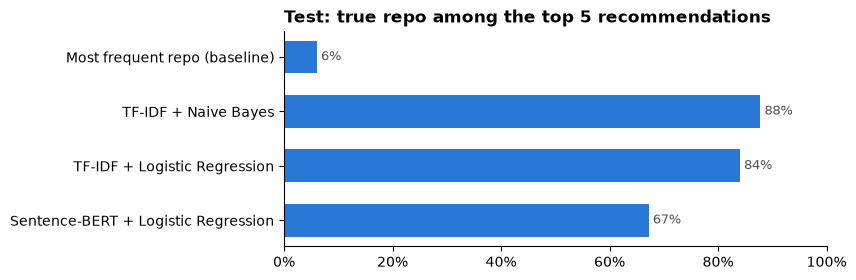

In [9]:
fig, ax = plt.subplots(figsize=(7, 2.8))
s = test_results["top-5 accuracy"].iloc[::-1]
ax.barh(s.index, s.values, color="#2a78d6", height=0.6)
for y, v in enumerate(s.values):
    ax.text(v, y, f" {v:.0%}", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.set_title("Test: true repo among the top 5 recommendations", loc="left", fontweight="bold");

In [10]:
out = ROOT / "results"
out.mkdir(exist_ok=True)
test_results.round(4).to_csv(out / "test_results.csv", index_label="model")
print("saved", (out / "test_results.csv").relative_to(ROOT))

saved results/test_results.csv


## 5. Which repos are easy or hard to recognise? (best model)

In [11]:
model = models[best]
pred = model.predict(test.text)
per_repo_f1 = pd.Series(f1_score(test.repo, pred, labels=model.classes_, average=None, zero_division=0),
                        index=model.classes_)
pd.DataFrame({"easiest (highest F1)": per_repo_f1.nlargest(8).round(2).reset_index().agg(lambda r: f"{r.iloc[0]} ({r.iloc[1]})", axis=1).values,
              "hardest (lowest F1)": per_repo_f1.nsmallest(8).round(2).reset_index().agg(lambda r: f"{r.iloc[0]} ({r.iloc[1]})", axis=1).values})

,easiest (highest F1),hardest (lowest F1)
0,apache/arrow (1.0),altair-viz/altair (0.0)
1,astral-sh/uv (1.0),bokeh/bokeh (0.0)
2,axios/axios (1.0),clap-rs/clap (0.0)
3,bevyengine/bevy (1.0),containerd/containerd (0.0)
4,cli/cli (1.0),derailed/k9s (0.0)
5,clickhouse/clickhouse (1.0),fastify/fastify (0.0)
6,cypress-io/cypress (1.0),grpc/grpc-go (0.0)
7,dotnet/aspnetcore (1.0),helm/helm (0.0)


In [12]:
mistakes = pd.DataFrame({"true repo": test.repo.values, "predicted": pred})
mistakes = mistakes[mistakes["true repo"] != mistakes["predicted"]]
mistakes.value_counts().head(10).rename("count").to_frame()

,,count
true repo,predicted,
pytest-dev/pytest,sympy/sympy,2
ocaml/ocaml,kubernetes/kubernetes,1
TanStack/query,traefik/traefik,1
argoproj/argo-cd,argoproj/argo-workflows,1
microsoft/typescript,webpack/webpack,1
apache/airflow,flutter/flutter,1
helm/helm,kubernetes/kubernetes,1
nestjs/nest,traefik/traefik,1
go-gitea/gitea,pnpm/pnpm,1


## 6. Takeaways

- **The task is learnable:** with 117 repos, guessing the most common repo is right 2% of the time. The
  tuned **TF-IDF + Naive Bayes** gets the exact repo right about **75%** of the time and has the true repo in
  its **top 5 for about 88%** of developers on the test set (exact numbers in §4).
- **What improved it** compared with the first version (PR text cut at 500 chars, single words, default
  settings → test accuracy 51%, top-5 73%, macro F1 0.36):
  1. **more text per developer** — full PR descriptions and the titles of issues they opened;
  2. **richer features** — word pairs and character 3–5-grams (code names such as `strftime`, `useState`);
  3. **light tuning** with cross-validation (Naive Bayes smoothing `alpha`, Logistic Regression `C`).
- **Honest check:** full PR descriptions contain each repo's **PR template**, which identifies the repo
  rather than the developer. Those template sentences are removed; keeping them would add about 5 points of
  accuracy earned by recognising templates, not skills.
- Macro F1 roughly doubled (0.36 → ~0.68): small repos are now recognised much better.
- Logistic Regression and Sentence-BERT stay behind; exact project and library words matter most.
- Limitation: the model is trained on PR text; a new user's profile is mostly their own repos and
  languages, so app recommendations are less reliable than these test numbers.